# LLM-JEPA: Custom Attention Mask (Section 3.2)
**Goal:** Test whether the block-causal attention mask prevents information transfer between Text and Code while allowing their representations to be computed in one joint attention operation.

**Hypothesis:** Changing only Text should alter Code representations under a standard causal mask, but not under the proposed mask. The proposed mask should also reproduce the outputs of separate processing.

This is a lightweight CPU experiment using a single scaled dot-product self-attention layer and synthetic token vectors, not a reproduction of full LLM training. The mask construction follows Section 3.2 of [LLM-JEPA](https://arxiv.org/abs/2509.14252).

In [1]:
import math
import torch
import matplotlib.pyplot as plt

# Small, deterministic CPU experiment
T, C, D = 4, 3, 16
DTYPE = torch.float64

def additive_mask(k):
    # Same triangular mask as in the paper
    mask = torch.zeros((k, k), dtype=DTYPE)
    mask[torch.triu(torch.ones(k, k), diagonal=1) == 1] = -torch.inf
    return mask

regular = additive_mask(T + C)
custom = torch.full_like(regular, -torch.inf)
custom[:T, :T] = additive_mask(T)
custom[T:, T:] = additive_mask(C)

print('Regular mask:\n', regular)
print('Custom mask:\n', custom)

Regular mask:
 tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0., 0., 0.]], dtype=torch.float64)
Custom mask:
 tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf],
        [-inf, -inf, -inf, -inf, 0., -inf, -inf],
        [-inf, -inf, -inf, -inf, 0., 0., -inf],
        [-inf, -inf, -inf, -inf, 0., 0., 0.]], dtype=torch.float64)


In [2]:
def attention(x, mask, weights):
    Wq, Wk, Wv = weights
    Q, K, V = x @ Wq, x @ Wk, x @ Wv
    scores = Q @ K.T / math.sqrt(D)
    A = torch.softmax(scores + mask, dim=-1)
    return A @ V, A


def experiment(seed):
    g = torch.Generator().manual_seed(seed)
    def rand(*shape):
        return torch.randn(*shape, generator=g, dtype=DTYPE)

    x = rand(T + C, D)
    weights = [rand(D, D) / math.sqrt(D) for _ in range(3)]
    changed = x.clone()
    changed[:T] += rand(T, D)  # Change Text only; keep Code fixed.

    r, Ar = attention(x, regular, weights)
    r2, _ = attention(changed, regular, weights)
    j, Aj = attention(x, custom, weights)
    j2, _ = attention(changed, custom, weights)
    text_only, _ = attention(x[:T], additive_mask(T), weights)
    code_only, _ = attention(x[T:], additive_mask(C), weights)
    separate = torch.cat([text_only, code_only])

    errors = torch.stack([
        (r[T:] - r2[T:]).abs().max(),
        (j[T:] - j2[T:]).abs().max(),
        (j - separate).abs().max(),
    ])
    return errors, Ar, Aj

errors, Ar, Aj = experiment(42)
labels = ['Regular: change Text', 'Custom: change Text', 'Custom vs separate']
for label, value in zip(labels, errors):
    print(f'{label:25s} {value.item():.6e}')
print(f'Regular: mean Code-to-Text attention mass = {Ar[T:, :T].sum(dim=-1).mean():.6f}')
print(f'Custom:  mean Code-to-Text attention mass = {Aj[T:, :T].sum(dim=-1).mean():.6f}')
assert errors[0] > 1e-8
assert torch.allclose(errors[1:], torch.zeros_like(errors[1:]), atol=1e-12, rtol=0)

Regular: change Text      2.459822e+00
Custom: change Text       0.000000e+00
Custom vs separate        0.000000e+00
Regular: mean Code-to-Text attention mass = 0.797294
Custom:  mean Code-to-Text attention mass = 0.000000


In [3]:
# Repeat with 30 different random seeds.
trials = torch.stack([experiment(s)[0] for s in range(30)])
means = trials.mean(dim=0)
for label, value, maximum in zip(labels, means, trials.max(dim=0).values):
    print(f'{label:25s} mean={value.item():.6e}, max={maximum.item():.6e}')
assert torch.all(trials[:, 0] > 1e-8)
assert torch.all(trials[:, 1:] < 1e-12)

Regular: change Text      mean=1.587614e+00, max=2.391048e+00
Custom: change Text       mean=0.000000e+00, max=0.000000e+00
Custom vs separate        mean=0.000000e+00, max=0.000000e+00


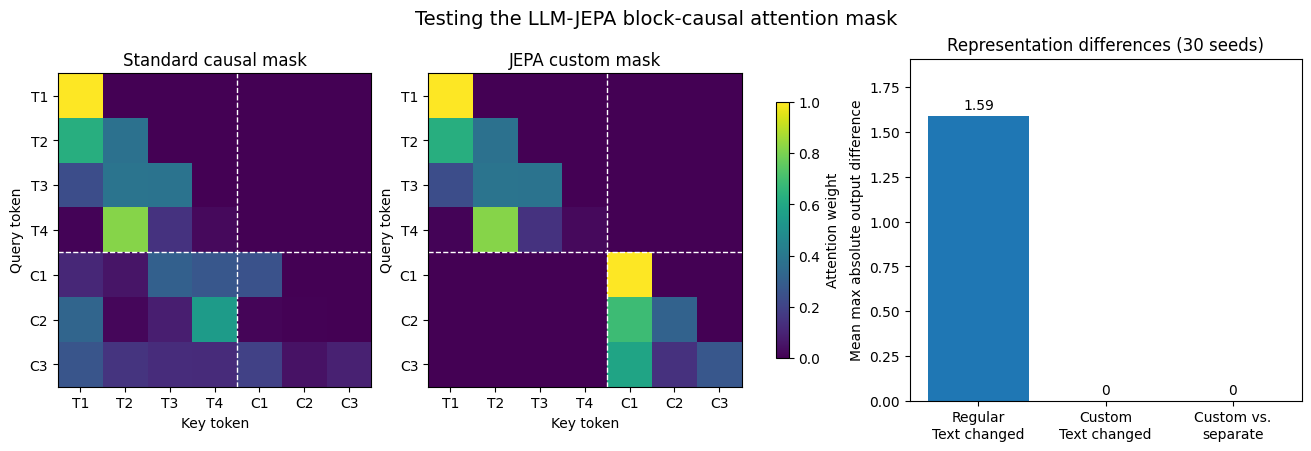

In [4]:
# Figure: actual attention weights and measured representation changes.
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), layout='constrained',
                         gridspec_kw={'width_ratios': [1, 1, 1.25]})
tokens = [f'T{i+1}' for i in range(T)] + [f'C{i+1}' for i in range(C)]
for ax, A, title in zip(axes[:2], [Ar, Aj], ['Standard causal mask', 'JEPA custom mask']):
    im = ax.imshow(A.numpy(), vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(range(T+C), tokens)
    ax.set_yticks(range(T+C), tokens)
    ax.axvline(T-.5, color='white', linestyle='--', linewidth=1)
    ax.axhline(T-.5, color='white', linestyle='--', linewidth=1)
    ax.set_xlabel('Key token')
    ax.set_ylabel('Query token')
    ax.set_title(title)
fig.colorbar(im, ax=axes[:2], shrink=.75, label='Attention weight')
ax = axes[2]
vals = means.numpy()
ax.bar(range(3), vals)
ax.set_xticks(range(3), ['Regular\nText changed', 'Custom\nText changed', 'Custom vs.\nseparate'])
ax.set_ylabel('Mean max absolute output difference')
ax.set_title('Representation differences (30 seeds)')
ax.set_ylim(0, max(vals)*1.2)
for i, v in enumerate(vals):
    ax.text(i, v+max(vals)*.025, f'{v:.3g}', ha='center', fontsize=10)
fig.suptitle('Testing the LLM-JEPA block-causal attention mask', fontsize=14)
fig.savefig('jepa_attention_results.png', dpi=180, bbox_inches='tight')
plt.show()

## Interpretation
The standard causal mask allows Code tokens to attend to earlier Text tokens. The custom mask blocks these cross-sequence attention weights, so changing Text has no effect on the Code output (up to numerical precision). Joint processing with the custom mask also matches separate processing for both sequences in this attention layer.

**Limitations:** Synthetic vectors and one attention layer without positional encodings. This verifies the masking mechanism, not speed, memory savings, downstream accuracy, or full-model equivalence. Real LLMs may require matching positional IDs and attention implementations. The paper uses a second forward pass for the JEPA loss in addition to the regular next-token prediction pass; this experiment tests only the masked attention component.